 <center>
    <h1>Improved Adult Census Income Prediction</h2>
 </center>

<h4>Task - </h4>The prediction task is to determine whether a person makes over $50K a year.
Given that the class imbalance is not severe and that both class labels are equally important, it is common to use classification accuracy or classification error to report model performance on this dataset.

<h4>Parameters - </h4>

* age: the age of an individual
* workclass: a general term to represent the employment status of an individual
* fnlwgt: final weight. This is the number of people the census believes the entry represents..
* education: the highest level of education achieved by an individual.
* education­num: the highest level of education achieved in numerical form.
* marital­status: marital status of an individual.
* occupation: the general type of occupation of an individual
* relationship: represents what this individual is relative to others.
* race: Descriptions of an individual’s race
* sex: the sex of the individual
* capital­gain: capital gains for an individual
* capital­loss: capital loss for an individual
* hours­per­week: the hours an individual has reported to work per week
* native­country: country of origin for an individual


### 26/04/26 - Changes:
- added more evaluation metrics (precision, recall, F1 score, PR AUC)
- removed unnecessary transformation (1/fnlwgt does nothing important), used log of capital diff
- added a new feature (is-married), not sure if it makes a difference yet
- fixed class imbalance (stratify=y in data splitting, class_weight='balanced' in model training)
- dropped fnlwgt (again not sure if this is good or bad yet)
- put the preprocessing within in the pipeline so data isn't encoded twice
- made the optimisation step score by roc_auc score (depends on which mertric we want to improve)
- made the optimised model actually use the best model from the optimisation step (baseline made a mistake here)

### Additional Fixes:
- updated some deprecated functions for the visuals (sns.distplot, sns.theme, etc)
- fixed the correlation heatmap (possibly just a python version issue from the baseline)

### Results: (see the end)
- accuracy and precision got worse (might not be great to show Naa)
- recall and pr auc is better

In [451]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler

In [452]:
data = pd.read_csv("adult_income_dataset.csv")
data

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [453]:
# Represents the number of rows and columns respectively.
data.shape

(32561, 15)

In [454]:
[(col, data[col].nunique(), data[col].dtype) for col in data.columns]

[('age', 73, dtype('int64')),
 ('workclass', 9, dtype('O')),
 ('fnlwgt', 21648, dtype('int64')),
 ('education', 16, dtype('O')),
 ('education.num', 16, dtype('int64')),
 ('marital.status', 7, dtype('O')),
 ('occupation', 15, dtype('O')),
 ('relationship', 6, dtype('O')),
 ('race', 5, dtype('O')),
 ('sex', 2, dtype('O')),
 ('capital.gain', 119, dtype('int64')),
 ('capital.loss', 92, dtype('int64')),
 ('hours.per.week', 94, dtype('int64')),
 ('native.country', 42, dtype('O')),
 ('income', 2, dtype('O'))]

In [455]:
# fnlwgt contains a high percentage of unique values, may be dropped later
data['fnlwgt'].nunique()/data.shape[0]*100

66.48444458094039

<h4><span style ="color:Darkblue;">Insights</span></h4>

<span style ="color:steelblue;">More than half the values are unique. This probably doesn't give a sigificant information about the data. But, later in feature engineering we will see if this feature holds any importance towards our goal.</span>

In [ ]:
# confirm mild class imbalance (24.1% to 75.9%), should use class_weight='balanced' in model training
data['income'].value_counts()
data['income'].value_counts(normalize=True) * 100

income
<=50K    75.919044
>50K     24.080956
Name: proportion, dtype: float64

In [457]:
data.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


<h4><span style ="color:Darkblue;">Insights</span></h4>

<span style = 'color:steelblue'> Count tell us if there's a missing data or not. All the numerical columns seems to have no missing data here. The mean and median tell us about the skewness in the data. For capital gain and capital loss, we can see that mean > median which happens when our data is right skewed. Rest of the columns seems fine. We can also say that our capital gain and capital loss are affected by outliers. ![Skewness.jpg](attachment:8c4a678a-1cfe-4e21-96b7-a69e552d0a11.jpg) </span>

### Numerical Variables EDA

#### AGE

Text(0.5, 0, 'Age')

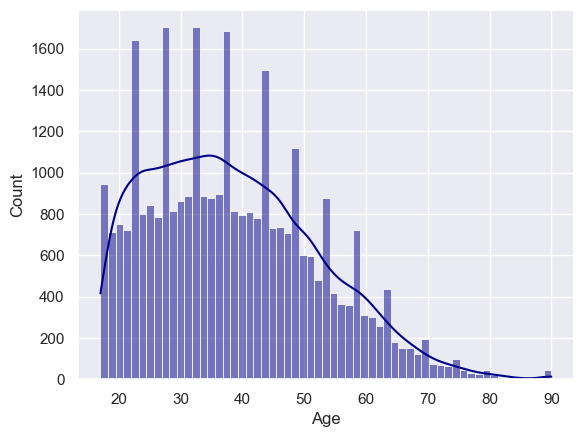

In [458]:
sns.histplot(data=data, x='age', kde=True, color='darkblue')
plt.xlabel('Age')

In [459]:
# We should make groups of age such that each group contains significant amount of 
# information.

print(len(data[(data['age'] > 16) & (data['age'] <= 25)]))
print(len(data[(data['age'] > 25) & (data['age'] <= 32)]))
print(len(data[(data['age'] > 32) & (data['age'] <= 40)]))
print(len(data[(data['age'] > 40) & (data['age'] <= 50)]))
print(len(data[(data['age'] > 50)]))

6411
5877
6830
6983
6460


#### FNLWGT (Final Weight)

Text(0.5, 0, 'Final Weight')

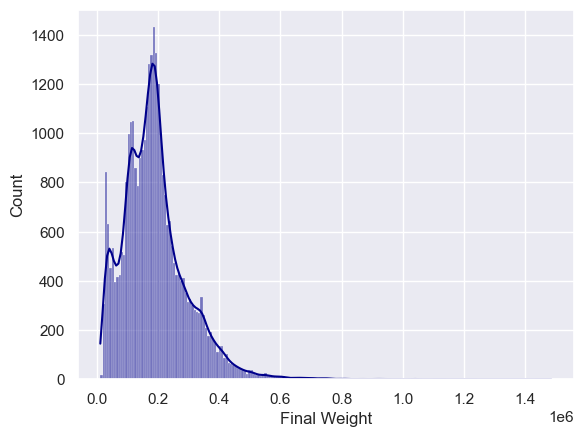

In [460]:
sns.histplot(data=data, x='fnlwgt', kde=True, color='darkblue')
plt.xlabel('Final Weight')

#### Education Num

Text(0.5, 0, 'Education Number')

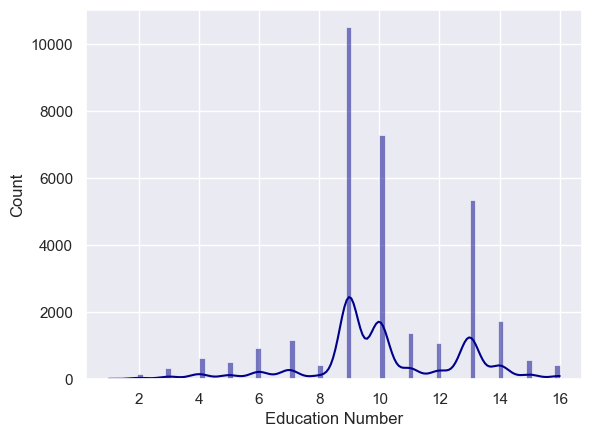

In [461]:
sns.histplot(data=data, x='education.num', kde=True, color='darkblue')
plt.xlabel('Education Number')

#### Capital Gain

Text(0.5, 0, 'Capital Gain')

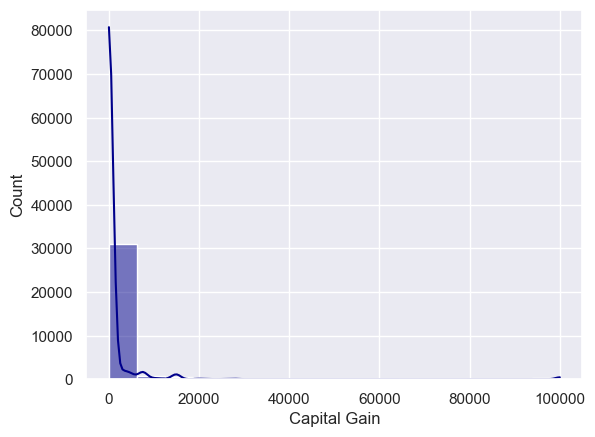

In [462]:
sns.histplot(data=data, x='capital.gain', kde=True, color='darkblue')
plt.xlabel('Capital Gain')

#### Capital Loss

Text(0.5, 0, 'Capital Loss')

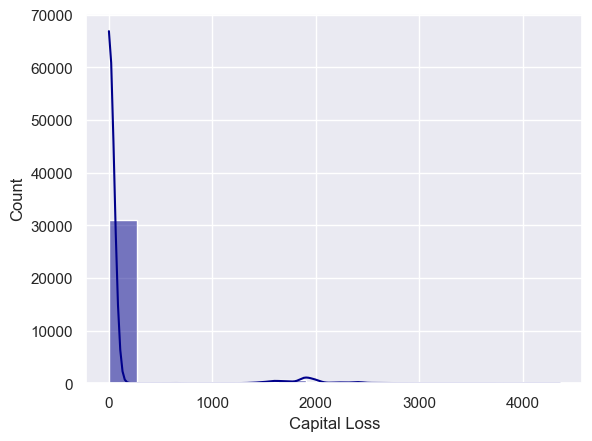

In [463]:
sns.histplot(data=data, x='capital.loss', kde=True, color='darkblue')
plt.xlabel('Capital Loss')

we see that final weight, capital gain, capital loss are right-skewed

#### Hours per-week

Text(0.5, 0, 'Number of Hours Worked per Week')

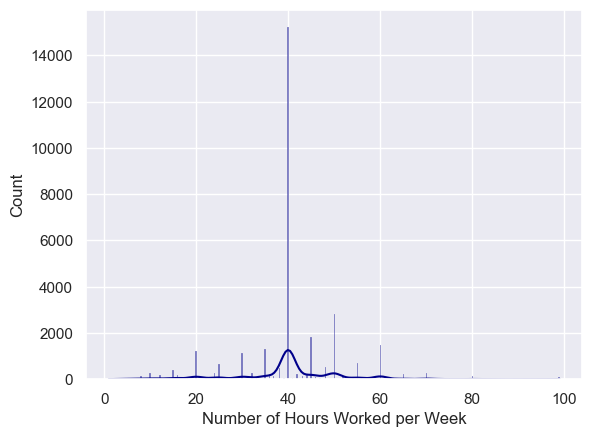

In [464]:
sns.histplot(data=data, x='hours.per.week', kde=True, color='darkblue')
plt.xlabel('Number of Hours Worked per Week')

### Specify the numerical and categorical variables

In [465]:
numerical_var = [col for col in data.columns if data[col].dtype != object]
categorical_var = [col for col in data.columns if data[col].dtype == object]
print(numerical_var)
print(categorical_var)

['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country', 'income']


<h3>Categorical Variables EDA</h3>

Here we have used barplot as well as countplot. Barplot which calculates the mean of the values in the particular columns. That's why we are getting values that are between 0 and 1. Countplot shows the number of observation in a category in a column.

#### Income

In [466]:
data['income'] = data['income'].apply(lambda x:x.replace("<=50K", "0"))
data['income'] = data['income'].apply(lambda x:x.replace(">50K", "1"))
data['income'] = data['income'].astype(int)

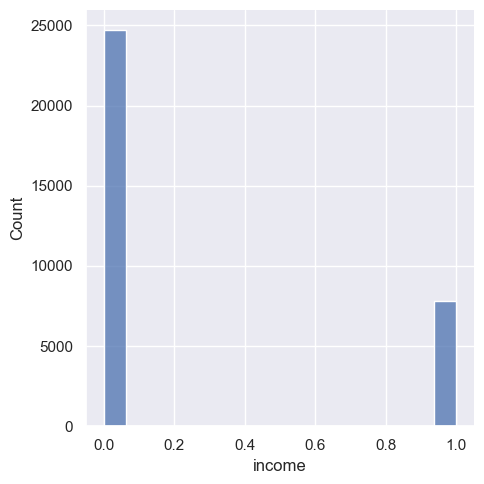

In [467]:
sns.displot(x = data['income'])

In [468]:
categorical_var

['workclass',
 'education',
 'marital.status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'native.country',
 'income']

In [469]:
[(i, data[i].unique()) for i in categorical_var]

[('workclass',
  array(['?', 'Private', 'State-gov', 'Federal-gov', 'Self-emp-not-inc',
         'Self-emp-inc', 'Local-gov', 'Without-pay', 'Never-worked'],
        dtype=object)),
 ('education',
  array(['HS-grad', 'Some-college', '7th-8th', '10th', 'Doctorate',
         'Prof-school', 'Bachelors', 'Masters', '11th', 'Assoc-acdm',
         'Assoc-voc', '1st-4th', '5th-6th', '12th', '9th', 'Preschool'],
        dtype=object)),
 ('marital.status',
  array(['Widowed', 'Divorced', 'Separated', 'Never-married',
         'Married-civ-spouse', 'Married-spouse-absent', 'Married-AF-spouse'],
        dtype=object)),
 ('occupation',
  array(['?', 'Exec-managerial', 'Machine-op-inspct', 'Prof-specialty',
         'Other-service', 'Adm-clerical', 'Craft-repair',
         'Transport-moving', 'Handlers-cleaners', 'Sales',
         'Farming-fishing', 'Tech-support', 'Protective-serv',
         'Armed-Forces', 'Priv-house-serv'], dtype=object)),
 ('relationship',
  array(['Not-in-family', 'Unmarried'

#### Workclass

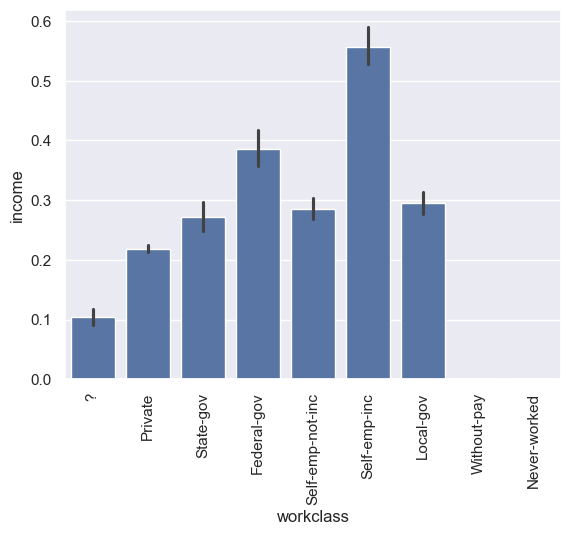

In [470]:
sns.barplot(x = 'workclass', y = 'income', data = data)
plt.xticks(rotation = 90);

#### Education

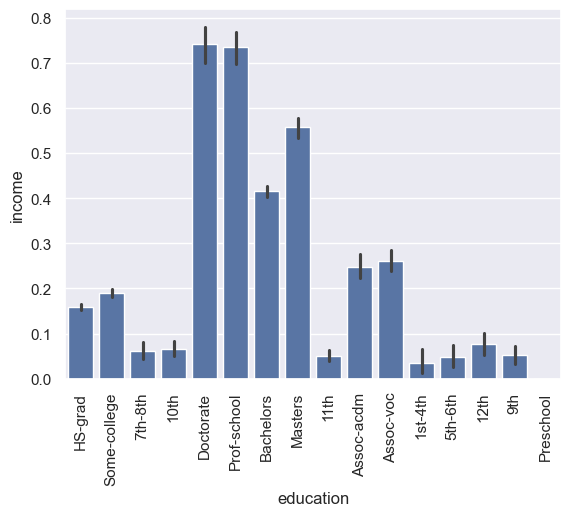

In [471]:
# For vertical bars categorical variables should be on xaxis.
# Hue is used to include another categorical variable in the graph.
sns.barplot(x = data['education'], y = data['income'])
plt.xticks(rotation = 90);

In [472]:
# Not a single person attending only preschool has an income >50k
len(data[(data['education'] == 'Preschool') & (data['income'] == 1)])

0

#### Marital Status

<span style = color:steelblue>
Here, Married-civ-spouse = when spouse is civilian.

Married-af-spouse = when spouse is in Armed Forces.</span>

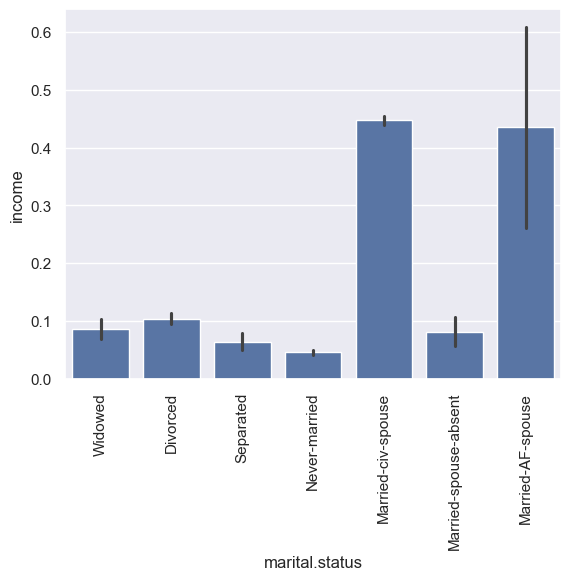

In [473]:
sns.barplot(x = 'marital.status', y = 'income', data = data)
plt.xticks(rotation = 90);

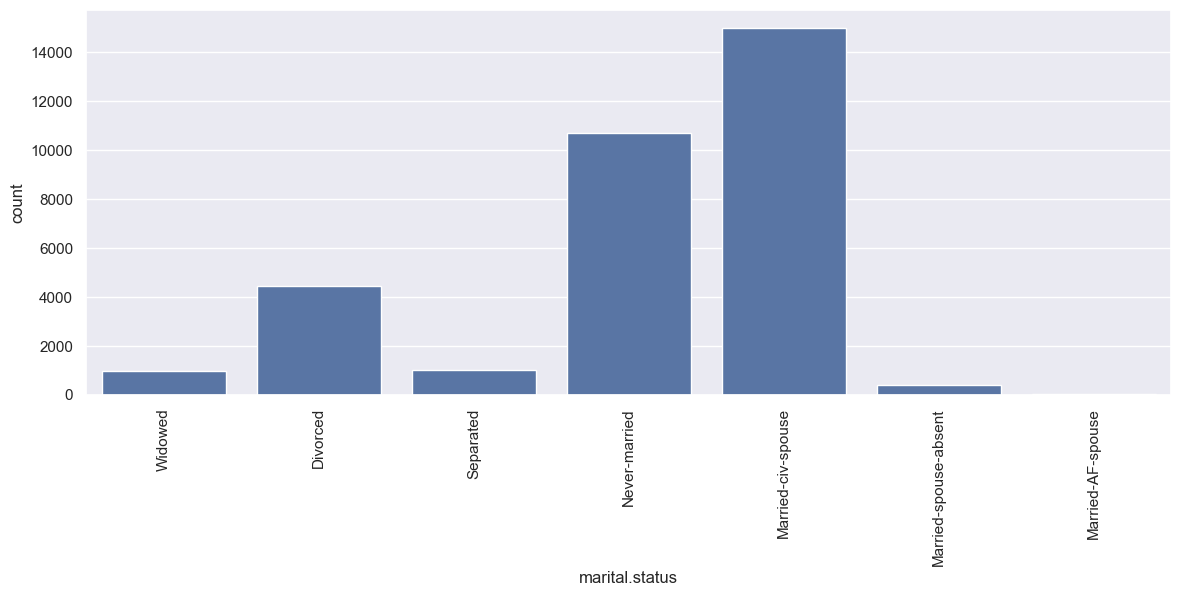

In [474]:
plt.figure(figsize = (14,5))

sns.countplot(x = 'marital.status', data = data);
plt.xticks(rotation = 90);

#### Relationship

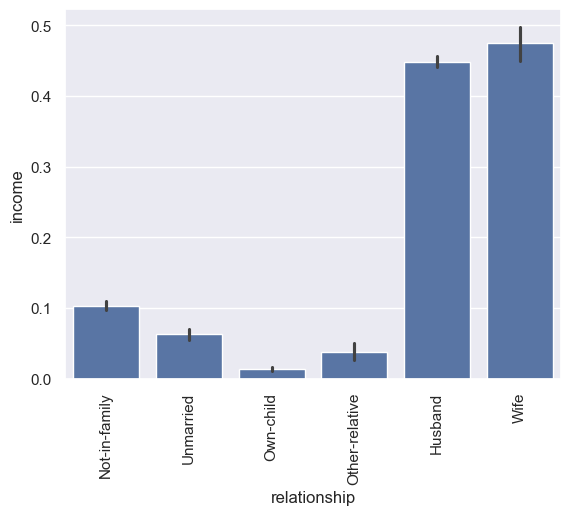

In [475]:
sns.barplot(x = 'relationship', y = 'income', data = data)
plt.xticks(rotation = 90);

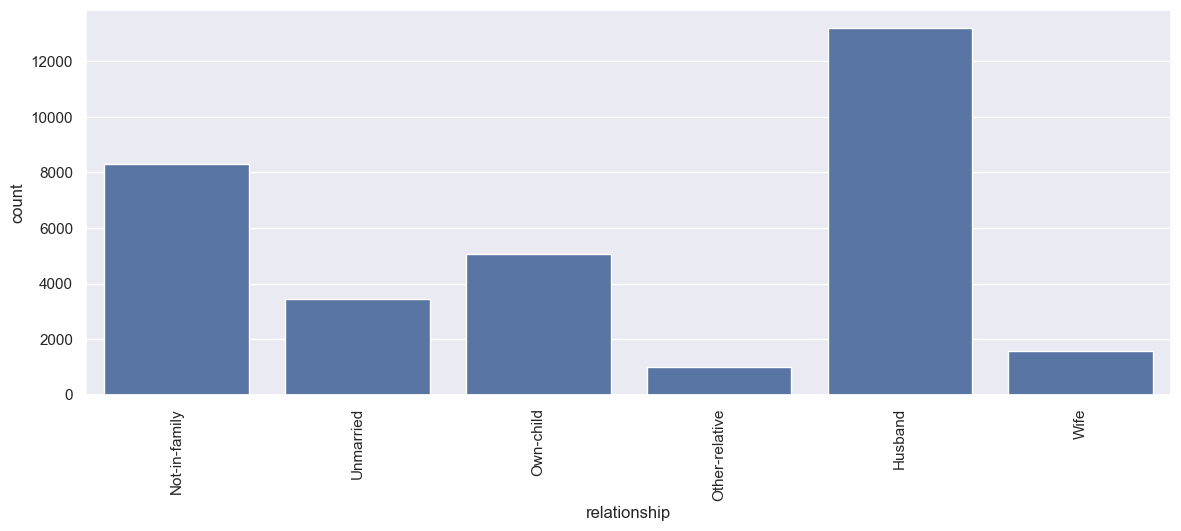

In [476]:
plt.figure(figsize = (14,5))

sns.countplot(x = 'relationship', data = data);
plt.xticks(rotation = 90);

#### Occupation

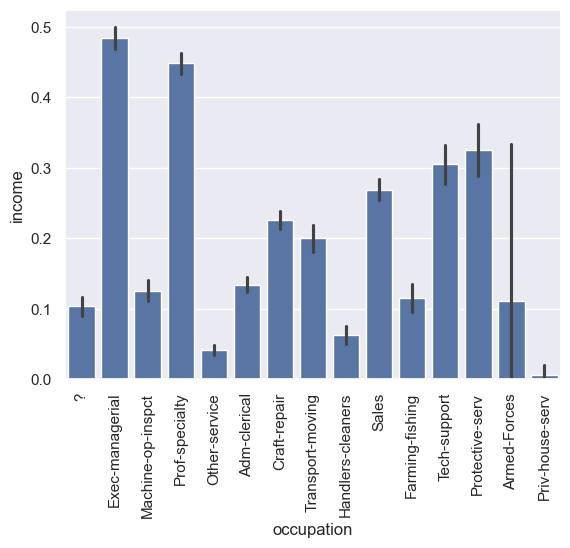

In [477]:
sns.barplot(x = 'occupation', y = 'income', data = data)
plt.xticks(rotation = 90);

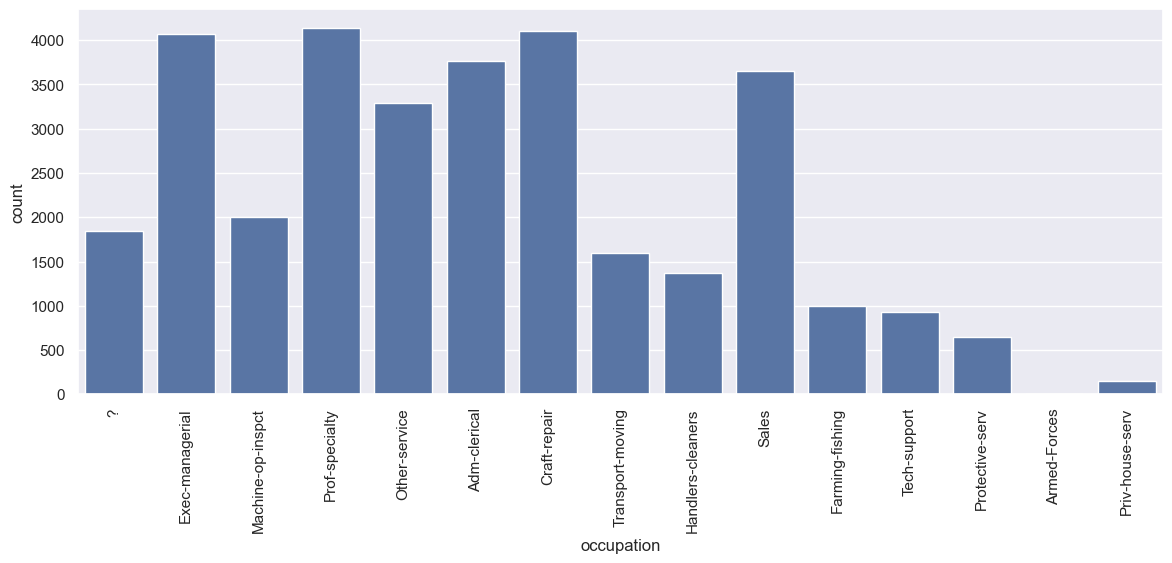

In [478]:
plt.figure(figsize = (14,5))

sns.countplot(x = 'occupation', data = data);
plt.xticks(rotation = 90);

#### Sex

<Axes: xlabel='sex', ylabel='income'>

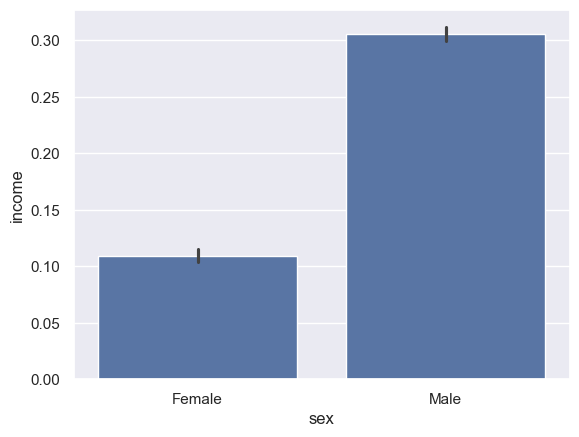

In [479]:
sns.set_theme(style = 'darkgrid', font_scale = 1)
sns.barplot(x = 'sex', y = 'income', data = data)

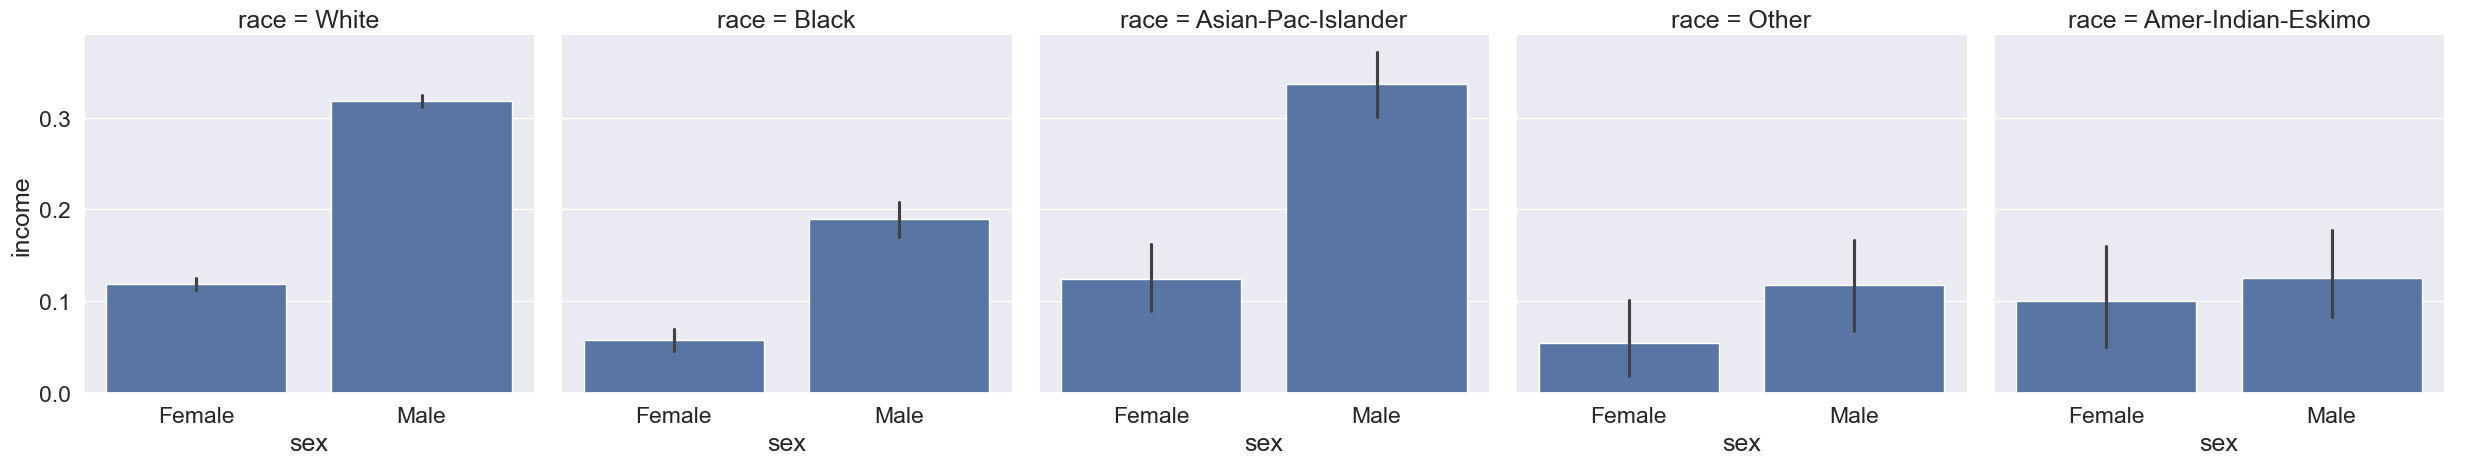

In [480]:
sns.set_theme(style = 'darkgrid', font_scale = 1.5)
sns.catplot(x = 'sex', y = 'income', data = data, kind = 'bar', col = 'race',
            height = 5, aspect = 1)

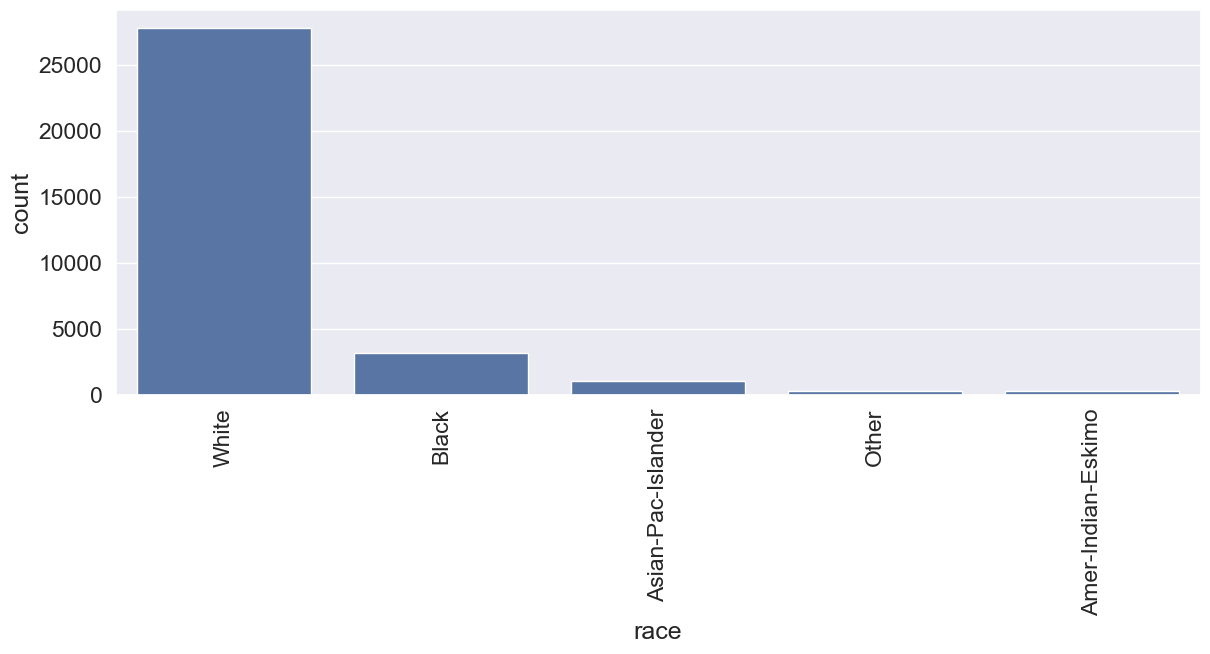

In [481]:
plt.figure(figsize = (14,5))

sns.countplot(x = 'race', data = data);
plt.xticks(rotation = 90);

#### Native Country

Text(0.5, 1.0, 'Country-wise Income')

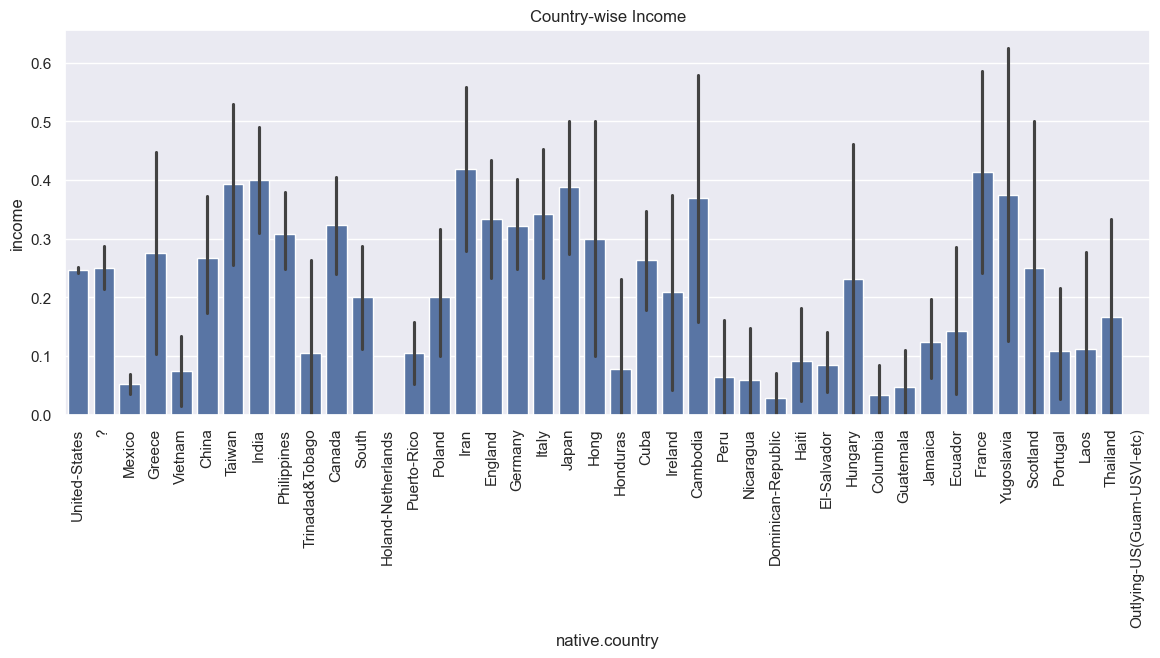

In [482]:
sns.set_theme(style = 'darkgrid', font_scale = 1)
plt.figure(figsize = (14,5))
sns.barplot(x = 'native.country', y = 'income', data = data);
plt.xticks(rotation = 90);
plt.title('Country-wise Income')

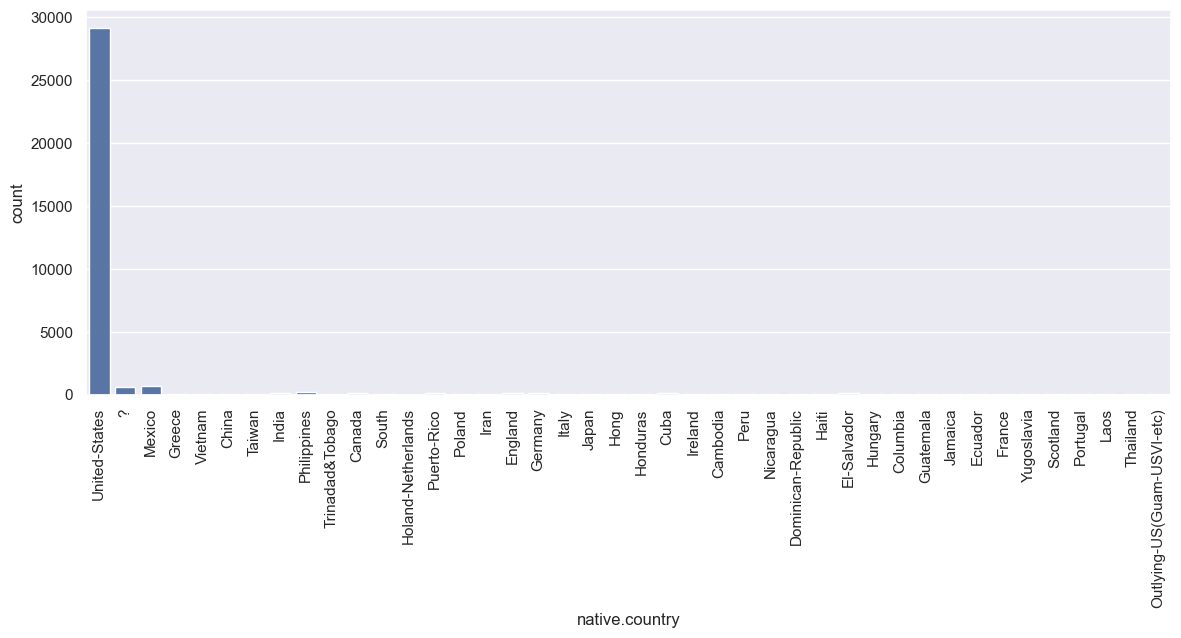

In [483]:
plt.figure(figsize = (14,5))

sns.countplot(x = 'native.country', data = data);
plt.xticks(rotation = 90);

### Feature Engineering

In [484]:
# age binning
data.loc[(data['age'] > 16) & (data['age'] <= 25), 'age'] = 1
data.loc[(data['age'] > 25) & (data['age'] <= 32), 'age'] = 2
data.loc[(data['age'] > 32) & (data['age'] <= 40), 'age'] = 3
data.loc[(data['age'] > 40) & (data['age'] <= 50), 'age'] = 4
data.loc[data['age'] > 50, 'age'] = 5

In [485]:
# education
data['education'] = data['education'].apply(lambda x: 'School' if x == '11th' or x == '7th-8th' or x == '10th' 
                                              or x == '5th-6th' or x == '9th' or x == '12th' or x == '1st-4th' 
                                              or x == 'Preschool' else x)
data['education'] = data['education'].apply(lambda x: 'Associate' if x == 'Assoc-acdm' or x == 'Assoc-voc' else x)
education_map = {'School':1,
             'HS-grad':2,
             'Some-college':3,
             'Bachelors':4,
             'Prof-school':5,
             'Associate':6,
             'Masters':7,
             'Doctorate':8}
data['education'] = data['education'].map(education_map)

In [486]:
# creating new feature
data['capital_diff'] = abs((data['capital.gain'] - data['capital.loss']))

In [487]:
# marital status
data['marital.status'] = data['marital.status'].apply(lambda x: 'Prev-Married' if (x == 'Widowed' or x == 'Divorced' or x == 'Separated') else x)
data['marital.status'] = data['marital.status'].apply(lambda x: 'Married' if (x == 'Married-civ-spouse' or x == 'Married-spouse-absent' or x == 'Married-AF-spouse') else x)

# new feature
data['is_married'] = (data['marital.status'] == 'Married').astype(int)

In [488]:
# workclass
data['workclass'] = data['workclass'].apply(lambda x: 'No income' if x == 'Never-worked' or x == 'Without-pay'
                                            else x)

In [490]:
# race
data['race'] = data['race'].apply(lambda x: 'Other' if x != 'White' else x)

In [491]:
# Percentage of people with ? in every column.
for col in data.columns:
    print((col, len(data[data[col] == '?'])/len(data[col])*100))

('age', 0.0)
('workclass', 5.638647461687294)
('fnlwgt', 0.0)
('education', 0.0)
('education.num', 0.0)
('marital.status', 0.0)
('occupation', 5.660145572924664)
('relationship', 0.0)
('race', 0.0)
('sex', 0.0)
('capital.gain', 0.0)
('capital.loss', 0.0)
('hours.per.week', 0.0)
('native.country', 0.0)
('income', 0.0)
('capital_diff', 0.0)
('is_married', 0.0)


In [492]:
# Converting ? to nan
data[data == '?'] = np.nan

In [493]:
col_with_symbol = ['workclass', 'occupation', 'native.country']

In [494]:
# Imputing ? with mode
for col in col_with_symbol:
    data[col].fillna(data[col].mode()[0], inplace=True)

<h4><span style ="color:Darkblue;">Insights</span></h4>

<span style = color:steelblue>The percetage of the entries with (?) is very low as compared to the length of the data of that particular columns. As we can see that the percentage in workclass, occupation, native.country are 6%, 6%, 2% respectively. Therefore, it seems that dropping the na values should be good choice but we can't be sure. So, check the score with and without dropping the columns and go for the one which gives better result.</span>

In [495]:
data[col_with_symbol].describe()

,workclass,occupation,native.country
count,32561,32561,32561
unique,7,14,2
top,Private,Prof-specialty,United-States
freq,24532,5983,29170


In [496]:
data.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income', 'capital_diff', 'is_married'],
      dtype='object')

### Handling Skewness

In [497]:
# handling skewness
data['capital.gain'] = np.log1p(data['capital.gain'])
data['capital.loss'] = np.log1p(data['capital.loss'])
data['capital_diff'] = np.log1p(data['capital_diff'])

In [ ]:
# native country
data['native.country'] = data['native.country'].apply(lambda x: 'Other' if x != 'United-States' else x)

In [498]:
data.describe()

,age,fnlwgt,education,education.num,capital.gain,capital.loss,hours.per.week,income,capital_diff,is_married
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,3.036977,1.897784e+05,3.116827,10.080679,0.734621,0.350305,40.437456,0.240810,1.084926,0.473481
std,1.405276,1.055500e+05,1.705080,2.572720,2.454738,1.584581,12.347429,0.427581,2.832302,0.499304
min,1.000000,1.228500e+04,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2.000000,1.178270e+05,2.000000,9.000000,0.000000,0.000000,40.000000,0.000000,0.000000,0.000000
50%,3.000000,1.783560e+05,3.000000,10.000000,0.000000,0.000000,40.000000,0.000000,0.000000,0.000000
75%,4.000000,2.370510e+05,4.000000,12.000000,0.000000,0.000000,45.000000,0.000000,0.000000,1.000000
max,5.000000,1.484705e+06,8.000000,16.000000,11.512925,8.379539,99.000000,1.000000,11.512925,1.000000


In [499]:
data

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,capital_diff,is_married
0,5,Private,77053,2,9,Prev-Married,Prof-specialty,Not-in-family,White,Female,0.0,8.379539,40,United-States,0,8.379539,0
1,5,Private,132870,2,9,Prev-Married,Exec-managerial,Not-in-family,White,Female,0.0,8.379539,18,United-States,0,8.379539,0
2,5,Private,186061,3,10,Prev-Married,Prof-specialty,Unmarried,Other,Female,0.0,8.379539,40,United-States,0,8.379539,0
3,5,Private,140359,1,4,Prev-Married,Machine-op-inspct,Unmarried,White,Female,0.0,8.268988,40,United-States,0,8.268988,0
4,4,Private,264663,3,10,Prev-Married,Prof-specialty,Own-child,White,Female,0.0,8.268988,40,United-States,0,8.268988,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,1,Private,310152,3,10,Never-married,Protective-serv,Not-in-family,White,Male,0.0,0.000000,40,United-States,0,0.000000,0
32557,2,Private,257302,6,12,Married,Tech-support,Wife,White,Female,0.0,0.000000,38,United-States,0,0.000000,1
32558,3,Private,154374,2,9,Married,Machine-op-inspct,Husband,White,Male,0.0,0.000000,40,United-States,1,0.000000,1
32559,5,Private,151910,2,9,Prev-Married,Adm-clerical,Unmarried,White,Female,0.0,0.000000,40,United-States,0,0.000000,0


### Correlation

<Axes: >

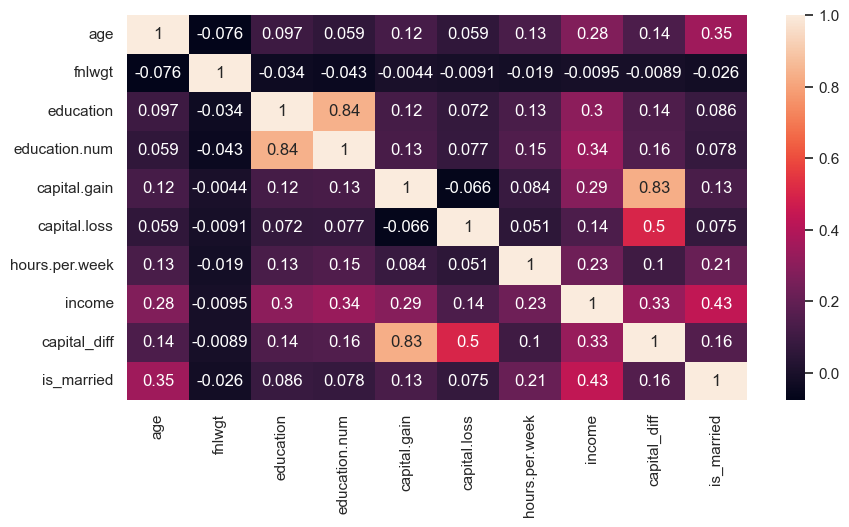

In [500]:
plt.figure(figsize = (10, 5))
# this threw an error in the original baseline because of the non-numeric columns, could be due to python version
# sns.heatmap(data.corr(), annot = True)
# fix:
sns.heatmap(data.select_dtypes(include=['number']).corr(), annot=True)

<h4><span style ="color:Darkblue;">Insights</span></h4>

<span style = color:steelblue>Education and Education num are highly correlated with each other. Therefore we should drop one of them in order to significance and uniqueness of the variable. We will see which one to drop in a few mintues.<spam/>

### Splitting of the Data

In [501]:
y = data['income']
X = data.drop('income', axis = 1)

In [502]:
category_var = [col for col in X.columns if X[col].dtypes == object]
category_var

['workclass',
 'marital.status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'native.country']

In [503]:
numeric_var = [col for col in X.columns if X[col].dtypes != object]
numeric_var

['age',
 'fnlwgt',
 'education',
 'education.num',
 'capital.gain',
 'capital.loss',
 'hours.per.week',
 'capital_diff',
 'is_married']

### Multi-Collinearity

<h4><span style ="color:Darkblue;">Insights</span></h4>

There is a presence of multicollinearity if the value of VIF > 10.

In [504]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calc_vif(X):

    # Calculating VIF
    vif = pd.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    return(vif)

In [505]:
dt = X[numeric_var]
calc_vif(dt)

,variables,VIF
0,age,5.897317
1,fnlwgt,3.765529
2,education,11.704453
3,education.num,29.132360
4,capital.gain,inf
5,capital.loss,inf
6,hours.per.week,10.460066
7,capital_diff,inf
8,is_married,2.248535


In [506]:
X = X.drop('fnlwgt', axis = 1)

In [507]:
#Deleting education num
X = X.drop('education.num', axis = 1)
numeric_var = [col for col in X.columns if X[col].dtypes != object]
numeric_var

['age',
 'education',
 'capital.gain',
 'capital.loss',
 'hours.per.week',
 'capital_diff',
 'is_married']

In [508]:
dt = X[numeric_var]
calc_vif(dt)

,variables,VIF
0,age,5.436942
1,education,4.055505
2,capital.gain,inf
3,capital.loss,inf
4,hours.per.week,6.311122
5,capital_diff,inf
6,is_married,2.240816


In [509]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score, f1_score
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 1, test_size = 0.2, stratify=y) 

### Encoding and Feature Scaling

In [510]:
# base pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

base_pipe = Pipeline([
    ('pre', ColumnTransformer([
    ('num', StandardScaler(), numeric_var),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), category_var)
])),
('clf', LogisticRegression(class_weight='balanced', random_state=1, max_iter=200))
])

base_pipe.fit(X_train, y_train)

,steps,"[('pre', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [511]:
pred_base = base_pipe.predict(X_test)
pred_base_proba = base_pipe.predict_proba(X_test)[:, 1]

In [512]:
# Logistic Regression
print('Accuracy Score: {0:0.3f}'. format(accuracy_score(y_test, pred_base)))
print('Precision Score: {0:0.3f}'. format(precision_score(y_test, pred_base)))
print('Recall Score: {0:0.3f}'. format(recall_score(y_test, pred_base)))
print('F1 Score: {0:0.3f}'. format(f1_score(y_test, pred_base)))
print('ROC AUC Score: {0:0.3f}'. format(roc_auc_score(y_test, pred_base_proba)))

Accuracy Score: 0.805
Precision Score: 0.563
Recall Score: 0.857
F1 Score: 0.679
ROC AUC Score: 0.902


### Optimization

In [513]:
from sklearn.model_selection import GridSearchCV


In [514]:
LogisticRegression().get_params().keys()

dict_keys(['C', 'class_weight', 'dual', 'fit_intercept', 'intercept_scaling', 'l1_ratio', 'max_iter', 'multi_class', 'n_jobs', 'penalty', 'random_state', 'solver', 'tol', 'verbose', 'warm_start'])

In [519]:
# new pipeline
pipe = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', StandardScaler(), numeric_var),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), category_var)
    ])),
    ('classifier', LogisticRegression())
])

# Create param grid.
param_grid = [
    {'classifier__penalty' : ['l1', 'l2', 'elasticnet'],
    'classifier__C' : [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
    'classifier__solver' : ['saga'],
    'classifier__l1_ratio' : [0.2, 0.5, 0.8],   # only active for elasticnet
    'classifier__class_weight' : ['balanced'],
    'classifier__random_state' : [1],
    'classifier__max_iter' : [50, 100, 150, 200]}
]

# Create grid search object
clf = GridSearchCV(pipe, param_grid = param_grid, cv = 5, scoring='roc_auc', verbose=True, n_jobs=-1)

# Fit on data
best_clf = clf.fit(X_train, y_train)

Fitting 5 folds for each of 288 candidates, totalling 1440 fits


In [520]:
best_clf.best_params_

{'classifier__C': 1.0,
 'classifier__class_weight': 'balanced',
 'classifier__l1_ratio': 0.2,
 'classifier__max_iter': 150,
 'classifier__penalty': 'l2',
 'classifier__random_state': 1,
 'classifier__solver': 'saga'}

In [ ]:
# optimal model results
pred_opt = best_clf.predict(X_test)
pred_opt_proba = best_clf.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, pred_opt)
prec = precision_score(y_test, pred_opt)
rec = recall_score(y_test, pred_opt)
f1 = f1_score(y_test, pred_opt)
roc_auc = roc_auc_score(y_test, pred_opt_proba)

print('Accuracy Score: {0:0.3f}'. format(acc))
print('Precision Score: {0:0.3f}'. format(prec))
print('Recall Score: {0:0.3f}'. format(rec))
print('F1 Score: {0:0.3f}'. format(f1))
print('ROC AUC Score: {0:0.3f}'.format(roc_auc))

Accuracy Score: 0.805
Precision Score: 0.563
Recall Score: 0.857
F1 Score: 0.679
ROC AUC Score: 0.902


In [524]:
results = pd.DataFrame({
    'Model'    : ['Baseline (original)', 'Baseline (improved)', 'Optimised'],
    'Accuracy' : [0.862, accuracy_score(y_test, pred_base), accuracy_score(y_test, pred_opt)],
    'Precision': [0.769, precision_score(y_test, pred_base), precision_score(y_test, pred_opt)],
    'Recall'   : [0.612, recall_score(y_test, pred_base), recall_score(y_test, pred_opt)],
    'F1'       : [0.682, f1_score(y_test, pred_base), f1_score(y_test, pred_opt)],
    'ROC AUC'  : [0.777, roc_auc_score(y_test, pred_base_proba), roc_auc_score(y_test, pred_opt_proba)],
}).round(3)
print(results)

                 Model  Accuracy  Precision  Recall     F1  ROC AUC
0  Baseline (original)     0.862      0.769   0.612  0.682    0.777
1  Baseline (improved)     0.805      0.563   0.857  0.679    0.902
2            Optimised     0.805      0.563   0.857  0.679    0.902
